# 05. Feature Importance

This notebook displays the trained XGBoost model's feature importance scores. Categorical features may appear as multiple one-hot encoded categories.

First run `03_model_training.ipynb`.

## 1. Import libraries and load the model

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

model = joblib.load("../pickle_file/food_delivery_xgboost.pkl")
print("Model loaded successfully.")

Model loaded successfully.


## 2. Extract feature names and importance scores

In [2]:
preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()
importance_values = regressor.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

importance_df["Importance (%)"] = (
    importance_df["Importance"] / importance_df["Importance"].sum() * 100
)

importance_df.head(15)

,Feature,Importance,Importance (%)
0,categorical__Traffic Level_Very High,0.511663,51.166271
1,categorical__Traffic Level_High,0.201375,20.137497
2,categorical__Traffic Level_Moderate,0.099882,9.988241
3,numeric__Distance,0.043629,4.362936
4,categorical__Order Type_Drinks,0.028678,2.867806
5,categorical__Traffic Level_Low,0.022788,2.278759
6,categorical__Traffic Level_Very Low,0.022528,2.252782
7,numeric__Temperature,0.008751,0.875076
8,categorical__Order Type_Meal,0.007721,0.772059
9,categorical__Weather Description_smoke,0.006652,0.665209


## 3. Plot the top 15 encoded features

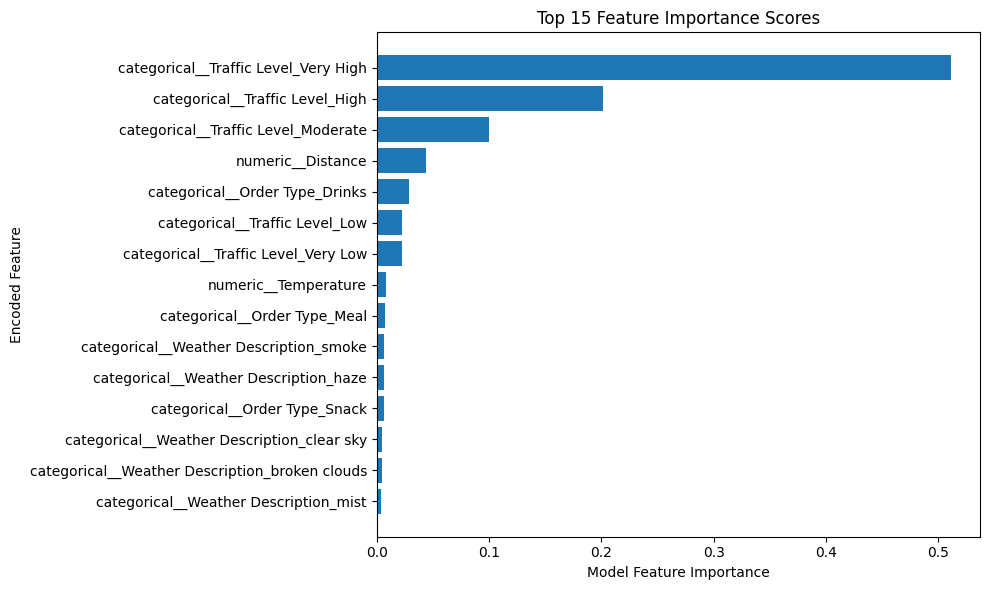

In [3]:
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Model Feature Importance")
plt.ylabel("Encoded Feature")
plt.title("Top 15 Feature Importance Scores")
plt.tight_layout()
plt.show()

## Important note

One original categorical column can create multiple encoded features, such as `Traffic Level_Low` and `Traffic Level_High`. This notebook shows those encoded features separately. Feature importance describes how the trained model uses features; it does not prove that a feature causes delivery time to change.